Import data

In [25]:
import importlib
import read_data
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    mean_squared_error,
    fbeta_score,
    recall_score,
    precision_score
)
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
importlib.reload(read_data)

<module 'read_data' from 'c:\\Users\\utente\\Documents\\GitHub\\FYS-STK3155--Project3--UiO\\code\\read_data.py'>

In [3]:
data = read_data.build_shared_datasets()

X_train = data["aggregate_trees"]["train"]
X_test  = data["aggregate_trees"]["test"]

y_train = data["y_class"]["train"]
y_test  = data["y_class"]["test"]

cv_folds = data["cv_folds"]

shared datasets: 10460 events | PCA keeps 49 of 96 columns for 95% variance | log10 on 15 columns | 77 sequence columns


In [3]:
print(X_train.shape)
print(X_train.columns.tolist())

(8293, 237)
['time_to_tca_mean', 'risk_mean', 'max_risk_estimate_mean', 'max_risk_scaling_mean', 'pc_1_mean', 'pc_2_mean', 'pc_3_mean', 'pc_4_mean', 'pc_5_mean', 'pc_6_mean', 'pc_7_mean', 'pc_8_mean', 'pc_9_mean', 'pc_10_mean', 'pc_11_mean', 'pc_12_mean', 'pc_13_mean', 'pc_14_mean', 'pc_15_mean', 'pc_16_mean', 'pc_17_mean', 'pc_18_mean', 'pc_19_mean', 'pc_20_mean', 'pc_21_mean', 'pc_22_mean', 'pc_23_mean', 'pc_24_mean', 'pc_25_mean', 'pc_26_mean', 'pc_27_mean', 'pc_28_mean', 'pc_29_mean', 'pc_30_mean', 'pc_31_mean', 'pc_32_mean', 'pc_33_mean', 'pc_34_mean', 'pc_35_mean', 'pc_36_mean', 'pc_37_mean', 'pc_38_mean', 'pc_39_mean', 'pc_40_mean', 'pc_41_mean', 'pc_42_mean', 'pc_43_mean', 'pc_44_mean', 'pc_45_mean', 'pc_46_mean', 'pc_47_mean', 'pc_48_mean', 'pc_49_mean', 'time_to_tca_std', 'risk_std', 'max_risk_estimate_std', 'max_risk_scaling_std', 'pc_1_std', 'pc_2_std', 'pc_3_std', 'pc_4_std', 'pc_5_std', 'pc_6_std', 'pc_7_std', 'pc_8_std', 'pc_9_std', 'pc_10_std', 'pc_11_std', 'pc_12_std',

In [4]:
print(y_train.shape)
print(y_test.shape)

(8293,)
(2167,)


In [5]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    min_child_weight=1,
    scale_pos_weight=1,
    random_state=42
)

baseline_cost = read_data.run_cv(model = model, X = X_train, y = y_train, cv_folds = cv_folds, threshold = 0.3)

In [6]:
depths = [3,4,5,6,7,8,9]
n_estimators=[50,75,100,125,150,175,200]

results = np.zeros((len(depths), len(n_estimators)))

for i, depth in enumerate(depths):
    for j, n in enumerate(n_estimators):

        model = XGBClassifier(
            n_estimators=n,
            max_depth=depth,
            learning_rate=0.3,
            min_child_weight=1,
            scale_pos_weight=1,
            random_state=42
        )

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

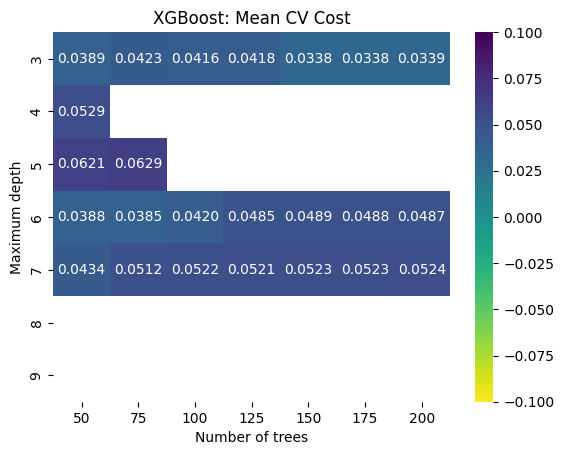

In [ ]:
#LLM generated:

sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=n_estimators,
    yticklabels=depths,
    cmap="viridis_r"
)

plt.xlabel("Number of trees")
plt.ylabel("Maximum depth")
plt.title("XGBoost: Mean CV Cost")
plt.show() 

In [11]:
learning_rates = [0.1, 0.2, 0.3, 0.4, 0.5]
n_estimators=[50,75,100,125,150]

results = np.full((len(learning_rates), len(n_estimators)), np.nan)

for i, lr in enumerate(learning_rates):
    for j, n in enumerate(n_estimators):

        model = XGBClassifier(
            n_estimators=n,
            max_depth=3,
            learning_rate=lr,
            min_child_weight=1,
            scale_pos_weight=1,
            random_state=42
        )

        print(lr, n)

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

0.1 50
0.1 75
0.1 100
0.1 125
0.1 150
0.2 50
0.2 75
0.2 100
0.2 125
0.2 150
0.3 50
0.3 75
0.3 100
0.3 125
0.3 150
0.4 50
0.4 75
0.4 100
0.4 125
0.4 150
0.5 50
0.5 75
0.5 100
0.5 125
0.5 150


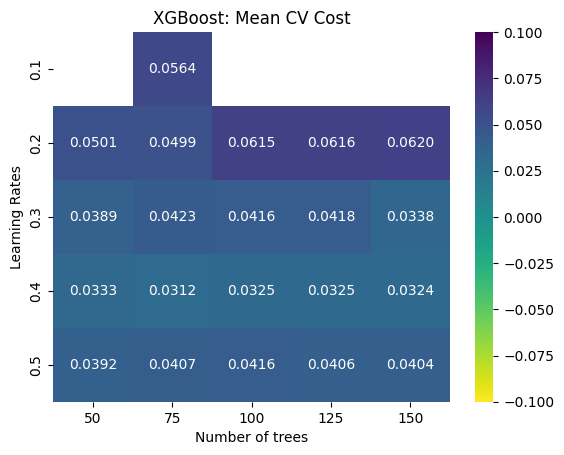

In [12]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=n_estimators,
    yticklabels=learning_rates,
    cmap="viridis_r"
)

plt.xlabel("Number of trees")
plt.ylabel("Learning Rates")
plt.title("XGBoost: Mean CV Cost")
plt.show() 

In [13]:
min_child_weights = [1,2,3,5,7,10]
depths=[3,4,5,6,7]

results = np.full((len(min_child_weights), len(depths)), np.nan)

for i, mc in enumerate(min_child_weights):
    for j, d in enumerate(depths):

        model = XGBClassifier(
            n_estimators=75,
            max_depth=d,
            learning_rate=0.4,
            min_child_weight=mc,
            scale_pos_weight=1,
            random_state=42
        )

        print(mc, d)

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

1 3
1 4
1 5
1 6
1 7
2 3
2 4
2 5
2 6
2 7
3 3
3 4
3 5
3 6
3 7
5 3
5 4
5 5
5 6
5 7
7 3
7 4
7 5
7 6
7 7
10 3
10 4
10 5
10 6
10 7


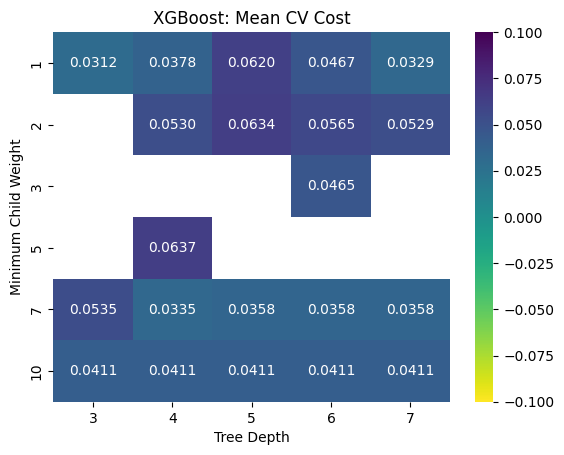

In [15]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=depths,
    yticklabels=min_child_weights,
    cmap="viridis_r"
)

plt.xlabel("Tree Depth")
plt.ylabel("Minimum Child Weight")
plt.title("XGBoost: Mean CV Cost")
plt.show()

In [17]:
scale_pos_weights = [1, 2, 5, 10, 20, 40, 60]
depths = [2, 3, 4, 5, 6]

results = np.zeros((len(scale_pos_weights), len(depths)))

for i, weight in enumerate(scale_pos_weights):
    for j, d in enumerate(depths):

        model = XGBClassifier(
            n_estimators=75,
            max_depth=d,
            learning_rate=0.4,
            min_child_weight=1,
            scale_pos_weight=weight,
            random_state=42
        )

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

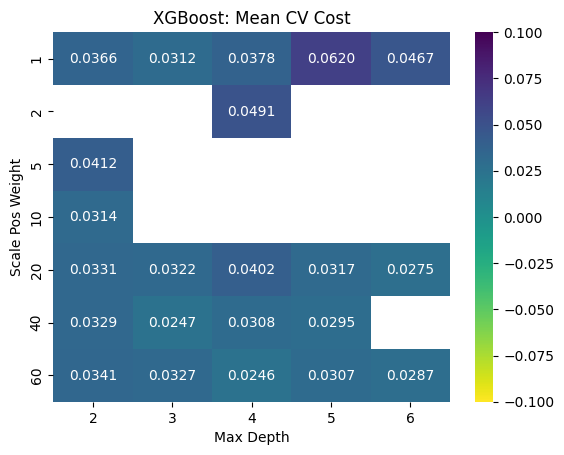

In [18]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=depths,
    yticklabels=scale_pos_weights,
    cmap="viridis_r"
)

plt.xlabel("Max Depth")
plt.ylabel("Scale Pos Weight")
plt.title("XGBoost: Mean CV Cost")
plt.show()

In [21]:
scale_pos_weights = [30, 35, 40, 45, 50, 55, 60, 65, 70, 80]
depths = [2, 3, 4, 5, 6]

results = np.zeros((len(scale_pos_weights), len(depths)))

for i, weight in enumerate(scale_pos_weights):
    for j, d in enumerate(depths):

        model = XGBClassifier(
            n_estimators=75,
            max_depth=d,
            learning_rate=0.4,
            min_child_weight=1,
            scale_pos_weight=weight,
            random_state=42
        )

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

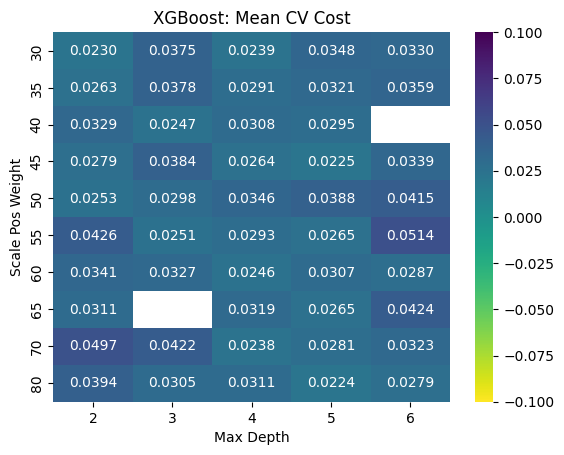

In [22]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=depths,
    yticklabels=scale_pos_weights,
    cmap="viridis_r"
)

plt.xlabel("Max Depth")
plt.ylabel("Scale Pos Weight")
plt.title("XGBoost: Mean CV Cost")
plt.show()

In [4]:
subsamples = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
colsamples = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

results = np.full((len(subsamples), len(colsamples)), np.nan)

for i, sub in enumerate(subsamples):
    for j, col in enumerate(colsamples):

        model = XGBClassifier(
            n_estimators=75,
            max_depth=4,
            learning_rate=0.4,
            min_child_weight=1,
            scale_pos_weight=45,
            subsample=sub,
            colsample_bytree=col,
            random_state=42
        )

        print(sub, col)

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

0.3 0.2
0.3 0.3
0.3 0.4
0.3 0.5
0.3 0.6
0.3 0.7
0.3 0.8
0.3 0.9
0.3 1.0
0.4 0.2
0.4 0.3
0.4 0.4
0.4 0.5
0.4 0.6
0.4 0.7
0.4 0.8
0.4 0.9
0.4 1.0
0.5 0.2
0.5 0.3
0.5 0.4
0.5 0.5
0.5 0.6
0.5 0.7
0.5 0.8
0.5 0.9
0.5 1.0
0.6 0.2
0.6 0.3
0.6 0.4
0.6 0.5
0.6 0.6
0.6 0.7
0.6 0.8
0.6 0.9
0.6 1.0
0.7 0.2
0.7 0.3
0.7 0.4
0.7 0.5
0.7 0.6
0.7 0.7
0.7 0.8
0.7 0.9
0.7 1.0
0.8 0.2
0.8 0.3
0.8 0.4
0.8 0.5
0.8 0.6
0.8 0.7
0.8 0.8
0.8 0.9
0.8 1.0
0.9 0.2
0.9 0.3
0.9 0.4
0.9 0.5
0.9 0.6
0.9 0.7
0.9 0.8
0.9 0.9
0.9 1.0
1.0 0.2
1.0 0.3
1.0 0.4
1.0 0.5
1.0 0.6
1.0 0.7
1.0 0.8
1.0 0.9
1.0 1.0


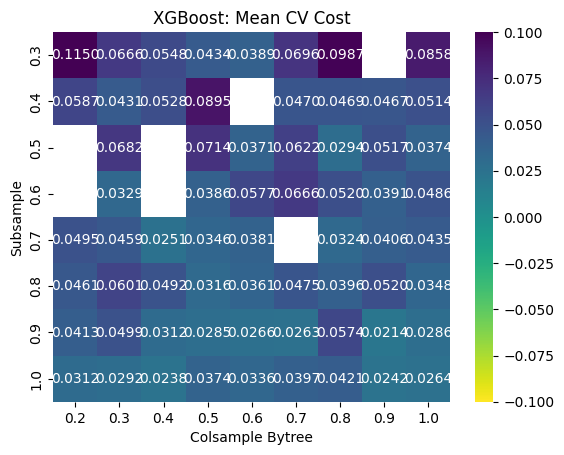

In [7]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=colsamples,
    yticklabels=subsamples,
    cmap="viridis_r"
)

plt.xlabel("Colsample Bytree")
plt.ylabel("Subsample")
plt.title("XGBoost: Mean CV Cost")
plt.show()


Gamma: 0

Gamma: 0.01

Gamma: 0.05

Gamma: 0.1

Gamma: 0.2

Gamma: 0.5

Gamma: 1

Gamma: 2

Gamma: 5

Gamma: 10

Final results:
Gamma     0: 0.02953
Gamma  0.01: 0.02970
Gamma  0.05: 0.03471
Gamma   0.1: 0.02977
Gamma   0.2: 0.02746
Gamma   0.5: 0.02323
Gamma     1: 0.02542
Gamma     2: 0.02741
Gamma     5: 0.02706
Gamma    10: 0.02819

Best gamma: 0.5
Best CV cost: 0.02323


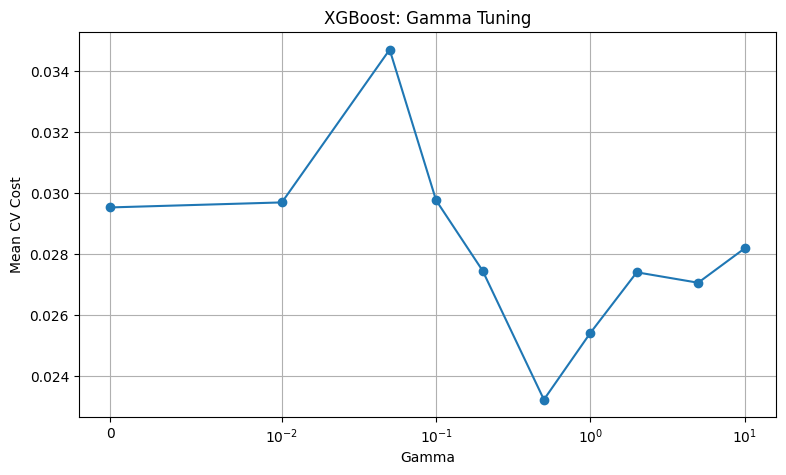

In [9]:
gammas = [0, 0.01, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10]

gamma_results = []

for gamma in gammas:

    model = XGBClassifier(
        n_estimators=75,
        max_depth=4,
        learning_rate=0.3,
        min_child_weight=1,
        scale_pos_weight=45,
        subsample=1.0,
        colsample_bytree=1.0,
        gamma=gamma,
        random_state=42
    )

    print(f"\nGamma: {gamma}")

    score = read_data.run_cv(
        model, X_train, y_train, cv_folds
    )

    gamma_results.append(score)

# Print results by ChatGPT
print("\nFinal results:")

for gamma, score in zip(gammas, gamma_results):
    print(f"Gamma {gamma:>5}: {score:.5f}")

best_idx = np.argmin(gamma_results)

print(f"\nBest gamma: {gammas[best_idx]}")
print(f"Best CV cost: {gamma_results[best_idx]:.5f}")

# Plot
plt.figure(figsize=(9, 5))

plt.plot(gammas, gamma_results, marker="o")

plt.xlabel("Gamma")
plt.ylabel("Mean CV Cost")
plt.title("XGBoost: Gamma Tuning")
plt.xscale("symlog", linthresh=0.01)
plt.grid(True)
plt.show()

In [10]:
reg_alphas = [0, 0.001, 0.01, 0.1, 1, 5, 10, 20]
reg_lambdas = [0.01, 0.1, 1, 5, 10, 20, 50, 100]

results = np.full((len(reg_alphas), len(reg_lambdas)), np.nan)

for i, alpha in enumerate(reg_alphas):
    for j, lamb in enumerate(reg_lambdas):

        model = XGBClassifier(
            n_estimators=75,
            max_depth=4,
            learning_rate=0.4,
            min_child_weight=1,
            scale_pos_weight=45,
            subsample=1.0,
            colsample_bytree=1.0,
            gamma=0.5,
            reg_alpha=alpha,
            reg_lambda=lamb,
            random_state=42
        )

        print(alpha, lamb)

        results[i, j] = read_data.run_cv(
            model, X_train, y_train, cv_folds
        )

0 0.01
0 0.1
0 1
0 5
0 10
0 20
0 50
0 100
0.001 0.01
0.001 0.1
0.001 1
0.001 5
0.001 10
0.001 20
0.001 50
0.001 100
0.01 0.01
0.01 0.1
0.01 1
0.01 5
0.01 10
0.01 20
0.01 50
0.01 100
0.1 0.01
0.1 0.1
0.1 1
0.1 5
0.1 10
0.1 20
0.1 50
0.1 100
1 0.01
1 0.1
1 1
1 5
1 10
1 20
1 50
1 100
5 0.01
5 0.1
5 1
5 5
5 10
5 20
5 50
5 100
10 0.01
10 0.1
10 1
10 5
10 10
10 20
10 50
10 100
20 0.01
20 0.1
20 1
20 5
20 10
20 20
20 50
20 100


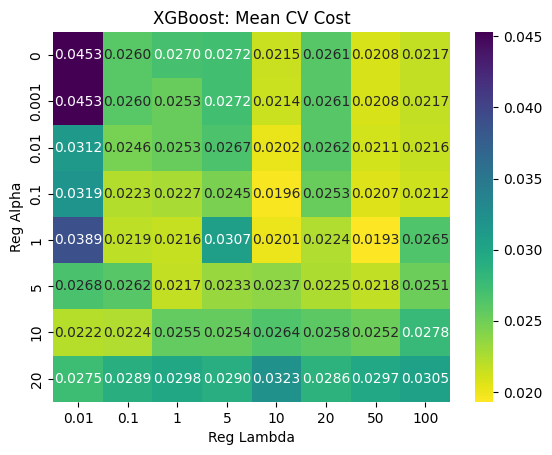

In [11]:
sns.heatmap(
    results,
    annot=True,
    fmt=".4f",
    xticklabels=reg_lambdas,
    yticklabels=reg_alphas,
    cmap="viridis_r"
)

plt.xlabel("Reg Lambda")
plt.ylabel("Reg Alpha")
plt.title("XGBoost: Mean CV Cost")
plt.show()


Lambda: 10

Lambda: 15

Lambda: 20

Lambda: 25

Lambda: 30

Lambda: 35

Lambda: 40

Lambda: 45

Lambda: 50

Lambda: 55

Lambda: 60

Lambda: 65

Lambda: 70

Lambda: 75

Lambda: 80

Lambda: 85

Lambda: 90

Lambda: 95

Lambda: 100

Final results:
Lambda  10: 0.02416
Lambda  15: 0.02521
Lambda  20: 0.02728
Lambda  25: 0.02506
Lambda  30: 0.02285
Lambda  35: 0.02194
Lambda  40: 0.02047
Lambda  45: 0.01983
Lambda  50: 0.01997
Lambda  55: 0.01966
Lambda  60: 0.01885
Lambda  65: 0.01877
Lambda  70: 0.01961
Lambda  75: 0.01994
Lambda  80: 0.02008
Lambda  85: 0.02298
Lambda  90: 0.02323
Lambda  95: 0.02247
Lambda 100: 0.02279

Best lambda: 65
Best CV cost: 0.01877


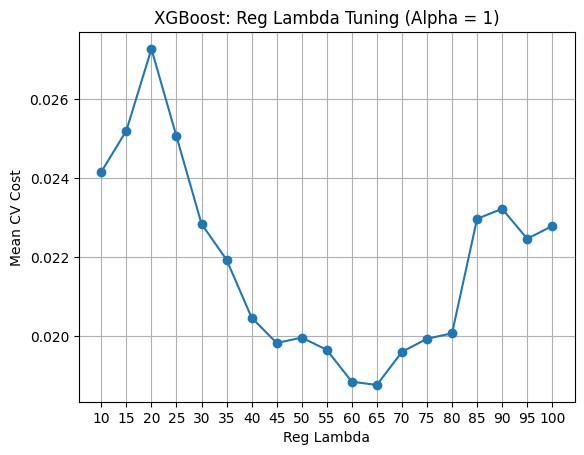

In [13]:
reg_lambdas = list(range(10, 101, 5))
reg_alpha = 1

lambda_results = []

for lamb in reg_lambdas:
    model = XGBClassifier(
        n_estimators=75,
        max_depth=4,
        learning_rate=0.4,
        min_child_weight=1,
        scale_pos_weight=45,
        subsample=1.0,
        colsample_bytree=1.0,
        gamma=0,
        reg_alpha=reg_alpha,
        reg_lambda=lamb,
        random_state=42
    )

    print(f"\nLambda: {lamb}")
    score = read_data.run_cv(model, X_train, y_train, cv_folds)
    lambda_results.append(score)

best_idx = np.argmin(lambda_results)

print("\nFinal results:")
for lamb, score in zip(reg_lambdas, lambda_results):
    print(f"Lambda {lamb:>3}: {score:.5f}")

print(f"\nBest lambda: {reg_lambdas[best_idx]}")
print(f"Best CV cost: {lambda_results[best_idx]:.5f}")

plt.plot(reg_lambdas, lambda_results, marker="o")
plt.xlabel("Reg Lambda")
plt.ylabel("Mean CV Cost")
plt.title("XGBoost: Reg Lambda Tuning (Alpha = 1)")
plt.xticks(reg_lambdas)
plt.grid(True)
plt.show()

Final Model

In [ ]:
model = XGBClassifier(
    n_estimators=75,
    max_depth=4,
    learning_rate=0.4,
    min_child_weight=1,
    scale_pos_weight=45,
    subsample=1.0,
    colsample_bytree=1.0,
    gamma=0,
    reg_alpha=1,
    reg_lambda=65,
    random_state=42
)

model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.3).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print(f"ROC-AUC: {roc_auc:.5f}")
print(f"PR-AUC:  {pr_auc:.5f}")

Confusion matrix:
[[1995   22]
 [  99   51]]

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      2017
           1       0.70      0.34      0.46       150

    accuracy                           0.94      2167
   macro avg       0.83      0.66      0.71      2167
weighted avg       0.94      0.94      0.94      2167

ROC-AUC: 0.94167
PR-AUC:  0.60216


Best threshold: 0.19
Best CV cost: 0.016559467746004305
Precision: 0.2619047619047619
Recall: 0.5
F2: 0.4230769230769231

Threshold 0.3:
Cost: 0.01741473695925947
Precision: 0.3333333333333333
Recall: 0.42424242424242425
F2: 0.40229885057471265


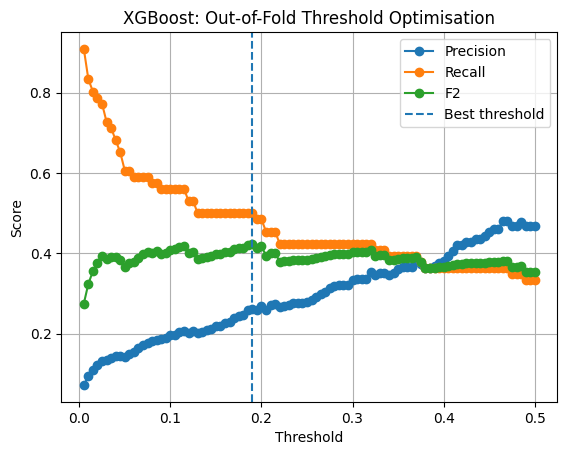

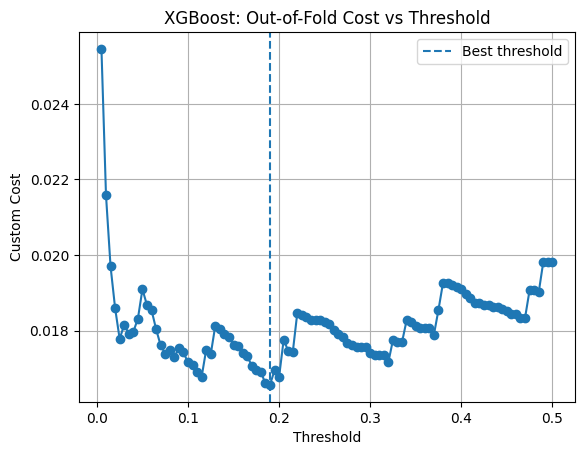

In [21]:

model = XGBClassifier(
    n_estimators=75,
    max_depth=4,
    learning_rate=0.4,
    min_child_weight=1,
    scale_pos_weight=45,
    subsample=1.0,
    colsample_bytree=1.0,
    gamma=0,
    reg_alpha=1,
    reg_lambda=65,
    random_state=42
)

# Generated by ChatGPT
y_train_array = np.asarray(y_train)
oof_prob = np.zeros(len(y_train_array))

for train_idx, val_idx in cv_folds:
    fold_model = XGBClassifier(
        n_estimators=75,
        max_depth=4,
        learning_rate=0.4,
        min_child_weight=1,
        scale_pos_weight=45,
        subsample=1.0,
        colsample_bytree=1.0,
        gamma=0,
        reg_alpha=1,
        reg_lambda=65,
        random_state=42
    )

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train_array[train_idx]
    )

    oof_prob[val_idx] = fold_model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

# Test thresholds
thresholds = np.arange(0.005, 0.501, 0.005)

mse = mean_squared_error(y_train_array, oof_prob)
results = []

for threshold in thresholds:
    y_pred = (oof_prob >= threshold).astype(int)

    precision = precision_score(y_train_array, y_pred, zero_division=0)
    recall = recall_score(y_train_array, y_pred, zero_division=0)
    f2 = fbeta_score(y_train_array, y_pred, beta=2, zero_division=0)

    cost = mse / f2 if f2 > 0 else float("inf")

    results.append([threshold, precision, recall, f2, cost])

results = np.array(results)

# Best threshold
best_idx = np.argmin(results[:, 4])

print("Best threshold:", results[best_idx, 0])
print("Best CV cost:", results[best_idx, 4])
print("Precision:", results[best_idx, 1])
print("Recall:", results[best_idx, 2])
print("F2:", results[best_idx, 3])

# Compare with threshold 0.3
idx_03 = np.argmin(np.abs(thresholds - 0.3))

print("\nThreshold 0.3:")
print("Cost:", results[idx_03, 4])
print("Precision:", results[idx_03, 1])
print("Recall:", results[idx_03, 2])
print("F2:", results[idx_03, 3])

# Plot precision, recall and F2
plt.plot(results[:, 0], results[:, 1], marker="o", label="Precision")
plt.plot(results[:, 0], results[:, 2], marker="o", label="Recall")
plt.plot(results[:, 0], results[:, 3], marker="o", label="F2")

plt.axvline(results[best_idx, 0], linestyle="--", label="Best threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("XGBoost: Out-of-Fold Threshold Optimisation")
plt.legend()
plt.grid(True)
plt.show()

# Plot custom cost
plt.plot(results[:, 0], results[:, 4], marker="o")
plt.axvline(results[best_idx, 0], linestyle="--", label="Best threshold")
plt.xlabel("Threshold")
plt.ylabel("Custom Cost")
plt.title("XGBoost: Out-of-Fold Cost vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Final model
model = XGBClassifier(
    n_estimators=75,
    max_depth=4,
    learning_rate=0.4,
    min_child_weight=1,
    scale_pos_weight=45,
    subsample=1.0,
    colsample_bytree=1.0,
    gamma=0,
    reg_alpha=1,
    reg_lambda=65,
    random_state=42
)

# Train on all training data
model.fit(X_train, y_train)

# Test predictions
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.19).astype(int)

# Classification results
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

# Metrics
mse = mean_squared_error(y_test, y_prob)
f2 = fbeta_score(y_test, y_pred, beta=2)
cost = mse / f2 if f2 > 0 else float("inf")

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print(f"MSE:       {mse:.5f}")
print(f"F2:        {f2:.5f}")
print(f"Cost:      {cost:.5f}")
print(f"ROC-AUC:   {roc_auc:.5f}")
print(f"PR-AUC:    {pr_auc:.5f}")

Confusion matrix:
[[1985   32]
 [  87   63]]

Classification report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      2017
           1       0.66      0.42      0.51       150

    accuracy                           0.95      2167
   macro avg       0.81      0.70      0.74      2167
weighted avg       0.94      0.95      0.94      2167

MSE:       0.04805
F2:        0.45324
Cost:      0.10601
ROC-AUC:   0.94167
PR-AUC:    0.60216


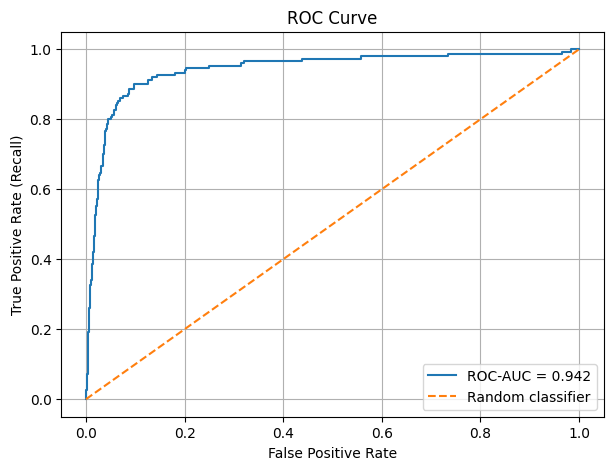

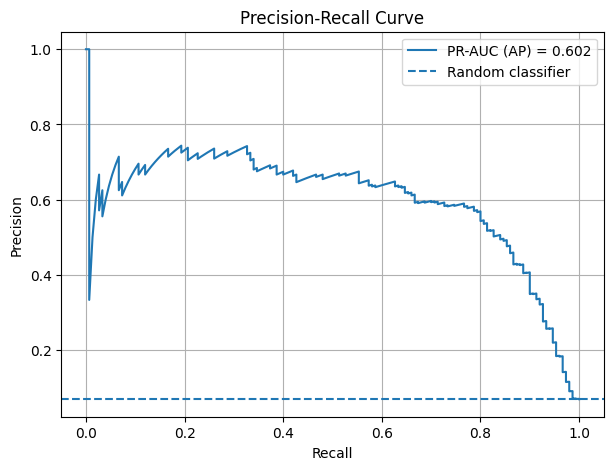

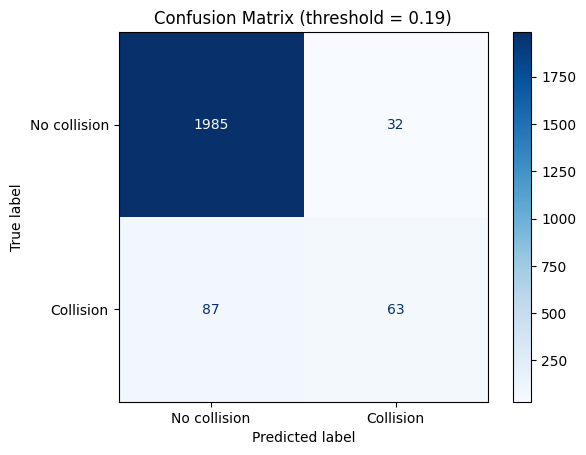

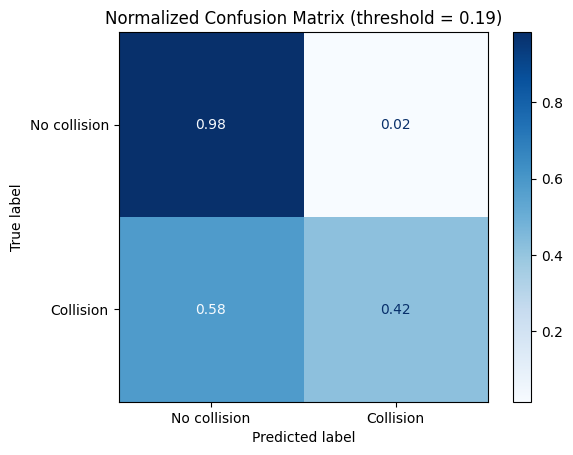

In [34]:
# Predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Classification threshold
threshold = 0.19
y_pred = (y_prob >= threshold).astype(int)

# 1. ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()


# 2. Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC (AP) = {pr_auc:.3f}")
plt.axhline(
    y_test.mean(),
    linestyle="--",
    label="Random classifier"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()


# 3. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No collision", "Collision"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix (threshold = {threshold})")
plt.show()

#Normalized
cm = confusion_matrix(y_test, y_pred, normalize="true")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No collision", "Collision"]
)

disp.plot(cmap="Blues", values_format=".2f")
plt.title(f"Normalized Confusion Matrix (threshold = {threshold})")
plt.show()